# Init

In [208]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [209]:
# Initialize processor
processor = SpectraDermaProcessor(sample_rate=50.0)

In [210]:
# Function to make color brighter
def make_color_brighter(color, factor=1.5):
    """
    Make a color brighter by multiplying RGB values by a factor.
    
    Args:
        color: RGB color (as tuple, list, or array)
        factor: Brightness multiplication factor
    
    Returns:
        numpy array of brighter RGB values, clipped to [0,1]
    """
    
    # Convert to numpy array and ensure it's RGB (not RGBA)
    rgb = mcolors.to_rgb(color)  # Take only RGB components
    rgb = np.array(rgb)
    
    # Multiply by factor and clip to valid range [0, 1]
    brighter_rgb = np.clip(rgb * factor, 0, 1)
    
    return brighter_rgb

# 555S2

In [12]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (390025, 6)
First few rows:
     0    1    2    3    4    5
0  1.0  2.0  5.0  6.0  6.0  4.0
1  1.0  2.0  5.0  6.0  6.0  4.0
2  1.0  2.0  5.0  6.0  6.0  4.0
3  1.0  2.0  5.0  6.0  6.0  4.0
4  1.0  2.0  5.0  6.0  6.0  4.0


In [22]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.5, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (390025, 6)


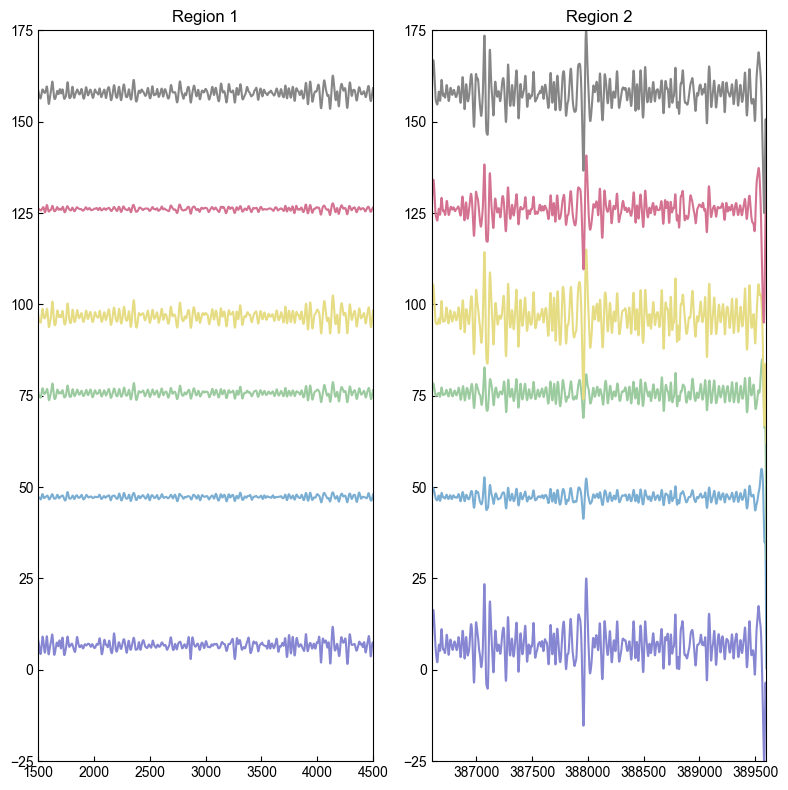

In [23]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 4500

ppg_region_start_2 = 386600
ppg_region_end_2 = 389600

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

#### 555S2 AC stats

In [27]:
from spectraderma_ppg_analyzer import SpectraDermaPPGAnalyzer

# Create analyzer instances for both regions
analyzer_1 = SpectraDermaPPGAnalyzer(sample_rate=50.0)
analyzer_2 = SpectraDermaPPGAnalyzer(sample_rate=50.0)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=2.5, order=3)

# Load data into both analyzers
analyzer_1.load_data(processor)
analyzer_2.load_data(processor)

# Set regions for 555S2
analyzer_1.set_region(ppg_region_start_1, ppg_region_end_1)
analyzer_2.set_region(ppg_region_start_2, ppg_region_end_2)

print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 555S2")
print("="*80)

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1 = analyzer_1.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_1 = analyzer_1.get_heart_rate()
print(f"Found {len(peaks_1)} peaks, Heart Rate: {heart_rate_1:.1f} BPM")

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2 = analyzer_2.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_2 = analyzer_2.get_heart_rate()
print(f"Found {len(peaks_2)} peaks, Heart Rate: {heart_rate_2:.1f} BPM")

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 555S2

REGION 1 ANALYSIS
Found 51 peaks, Heart Rate: 64.6 BPM

REGION 2 ANALYSIS
Found 53 peaks, Heart Rate: 61.0 BPM



PEAK VISUALIZATION

Region 1 Visualization:


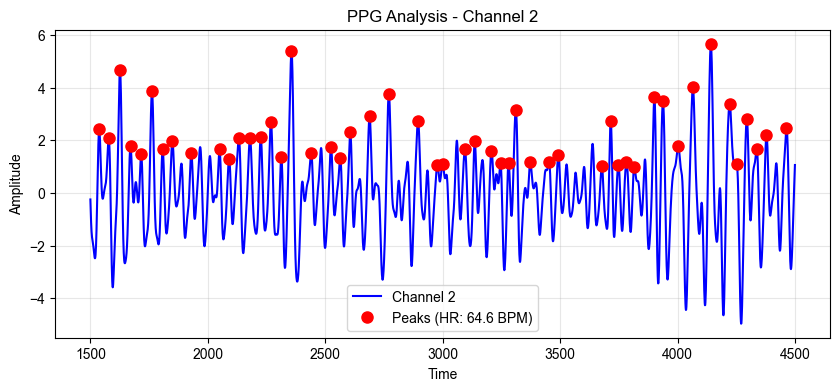


Region 2 Visualization:


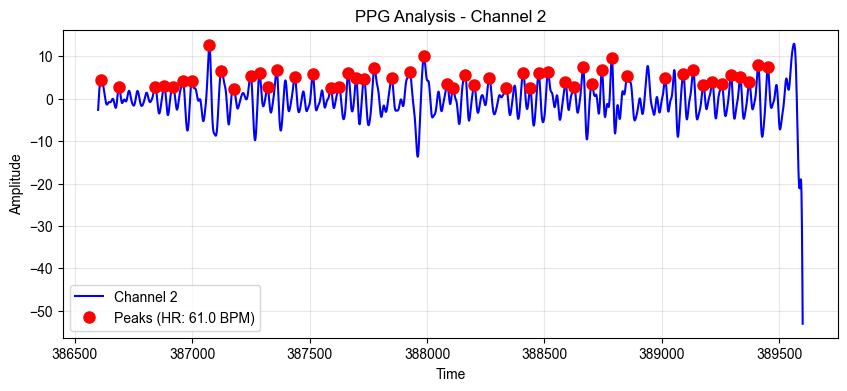

In [28]:
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

# Plot peaks for both regions using the simplified analyzer
if len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    analyzer_1.plot_peaks(channel_idx=2)

if len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    analyzer_2.plot_peaks(channel_idx=2)

#### 555S2 segmentation

REGION 1 - OVERLAID WAVEFORM SEGMENTS


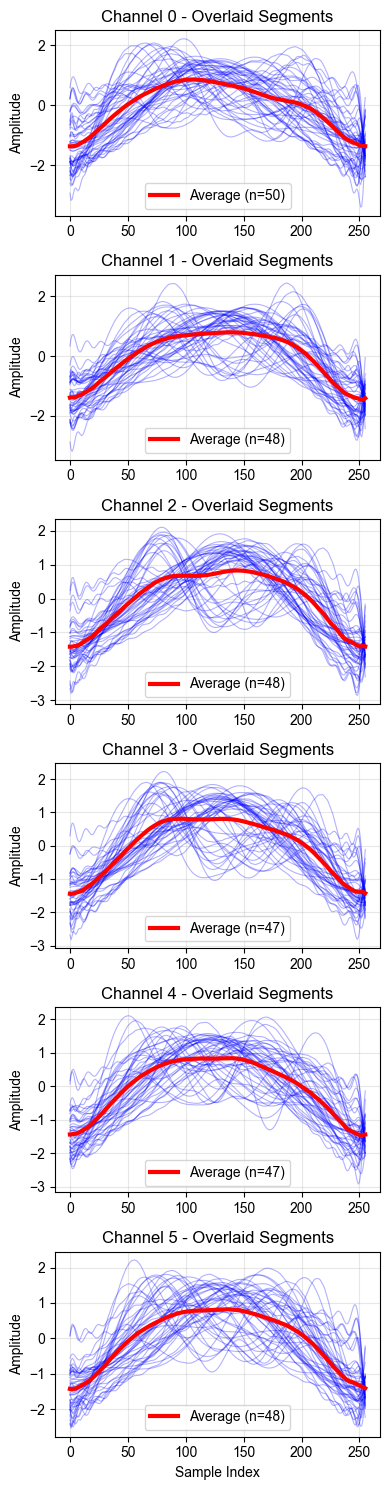

REGION 2 - OVERLAID WAVEFORM SEGMENTS


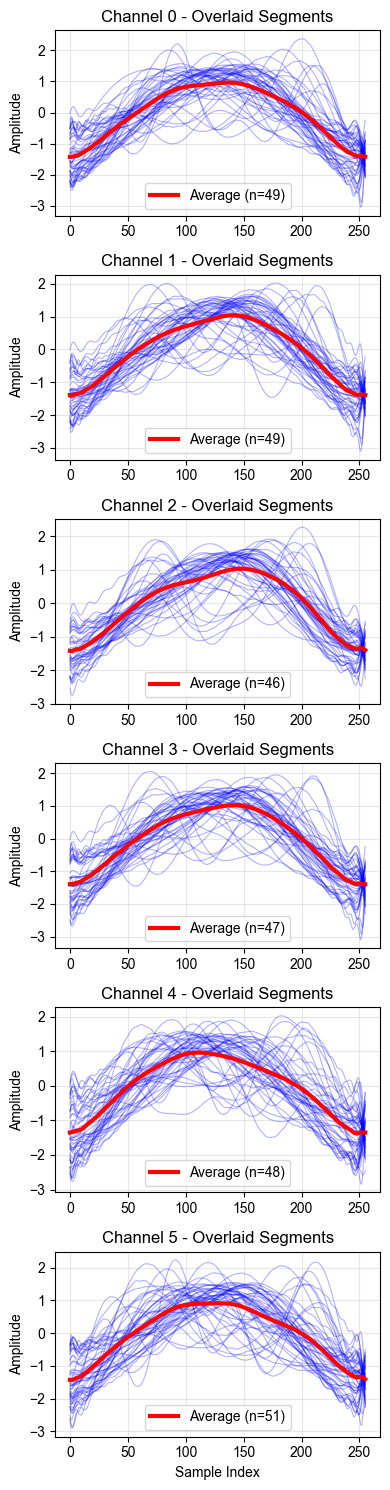

In [29]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 1 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_1.segment(outlier_sigma=0.5)
analyzer_1.plot_segments()

print("="*60)
print("REGION 2 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_2.segment(outlier_sigma=0.5)
analyzer_2.plot_segments()

##### save 555S2 segments

In [30]:
analyzer_1.compile(save_path="../data/ppg_segments/555S2/normal.pt", processor=processor, num_augmentation=50)
analyzer_2.compile(save_path="../data/ppg_segments/555S2/alcohol.pt", processor=processor, num_augmentation=50)

Original metadata peek (first 5 samples, all channels):
  Sample 0: Heights=[0.31738741 0.43598214 2.41979343 3.73100141 1.18613125 0.32613671]
            Intervals=[0. 0. 0. 0. 0. 0.]
            Widths=[0.35625875 0.34883668 0.39843516 0.25107494 0.36651697 0.24823499]
  Sample 1: Heights=[0.36282738 0.2315156  2.08843533 3.83732305 2.88045129 0.59994927]
            Intervals=[0.74 0.86 0.8  0.8  0.62 0.74]
            Widths=[0.32839191 0.44691274 0.26705561 0.4317474  0.35780178 1.07122153]
  Sample 2: Heights=[0.40123498 0.40326296 4.67524686 7.09549891 2.11814041 0.99538875]
            Intervals=[0.98 0.9  0.96 0.98 1.   1.  ]
            Widths=[0.49435521 0.422678   0.3751834  0.38075512 0.327293   0.40466946]
  Sample 3: Heights=[0.10807132 0.34339926 1.76473046 3.02756113 1.35523037 0.18837405]
            Intervals=[0.86 0.9  0.9  0.9  0.86 0.88]
            Widths=[0.21885968 0.32108663 0.36903192 0.3847813  0.28044877 0.23557791]
  Sample 4: Heights=[0.30376966 0.219649

tensor([[[-1.3534, -1.3767, -1.1536, -1.3439, -1.3572, -1.4376],
         [-1.2908, -1.2102, -1.0010, -1.1704, -1.3140, -1.4060],
         [-1.2178, -1.2167, -1.0106, -1.2802, -1.2494, -1.3380],
         ...,
         [-1.4631, -2.5127, -2.2239, -2.7317, -1.3610, -1.3377],
         [-1.4397, -2.1443, -1.8667, -2.4271, -1.3767, -1.3942],
         [-1.4034, -1.7189, -1.4688, -1.8522, -1.3774, -1.4316]],

        [[-1.9769, -1.3338, -1.3397, -1.1999, -2.3721, -1.6885],
         [-2.0842, -1.3282, -1.3244, -1.1665, -2.3324, -1.7274],
         [-2.0167, -1.3243, -1.3150, -1.1461, -2.3292, -1.6758],
         ...,
         [-1.1241, -1.3605, -1.4150, -1.3636, -2.5817, -1.2862],
         [-1.3316, -1.3503, -1.3865, -1.3013, -2.5466, -1.3868],
         [-1.6776, -1.3413, -1.3608, -1.2456, -2.4578, -1.5512]],

        [[-1.3021, -2.1162, -1.7851, -2.2864, -0.9020, -1.9976],
         [-1.2762, -2.2389, -1.8368, -2.4191, -0.8431, -1.9256],
         [-1.2595, -2.2969, -1.8628, -2.4856, -0.8094, -1.

##### visualize augmentation

Loaded 2499 samples with 256 time points and 6 channels


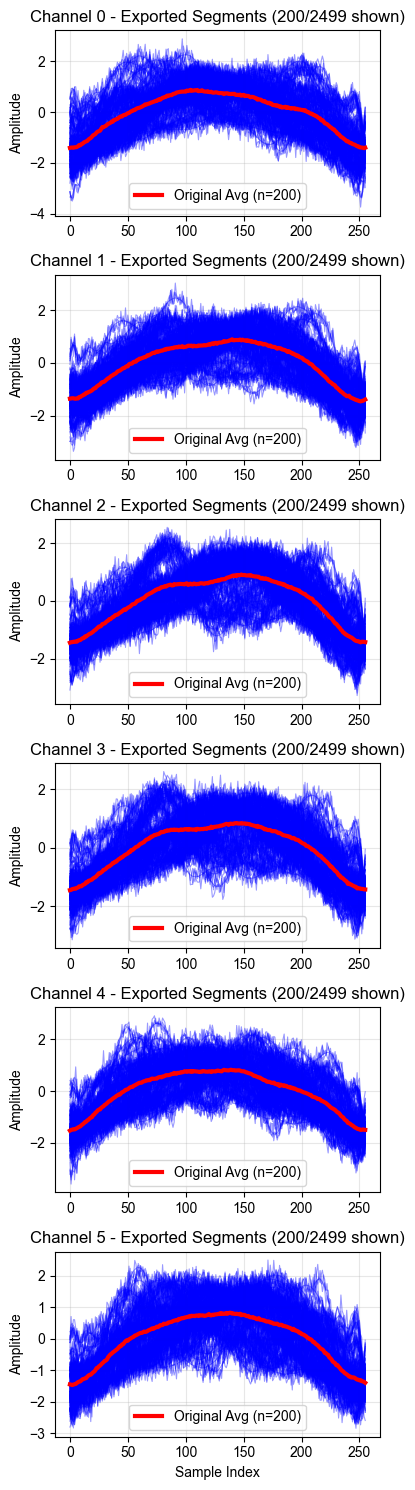

In [12]:
analyzer_1.plot_augmented_samples(data_path="../data/ppg_segments/555S2/normal.pt", max_samples=200)

# 520S2

In [211]:
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (426807, 6)
First few rows:
      0     1     2      3      4     5
0  29.0  32.0  83.0  277.0  465.0  78.0
1  29.0  32.0  83.0  277.0  465.0  78.0
2  28.0  31.0  80.0  267.0  448.0  76.0
3  28.0  31.0  80.0  267.0  447.0  75.0
4  28.0  31.0  80.0  267.0  449.0  75.0


In [212]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (426807, 6)


In [213]:
t1 = 250
t2 = 423000
d = 500

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (426807, 6)


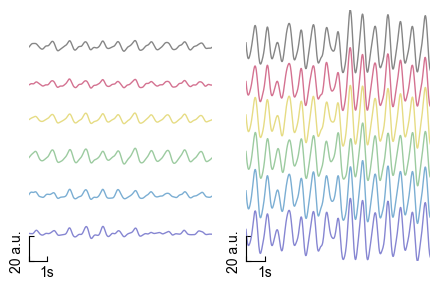

In [214]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + sample_rate)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + sample_rate])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + sample_rate)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + sample_rate])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


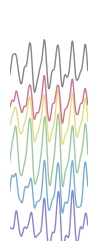

In [215]:
amplitude_limits = (-5, 30)

y_offset = 5

fig, ax = plt.subplots(figsize=(1, 3))

for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax.set_xlim(time_limits_1[0], time_limits_1[1] - 250)
ax.set_ylim(*amplitude_limits)

ax.set_axis_off()
# plt.savefig('../figures/fig3/diagram/mwppg_example.png', dpi=600, bbox_inches='tight', pad_inches=0)
plt.show()

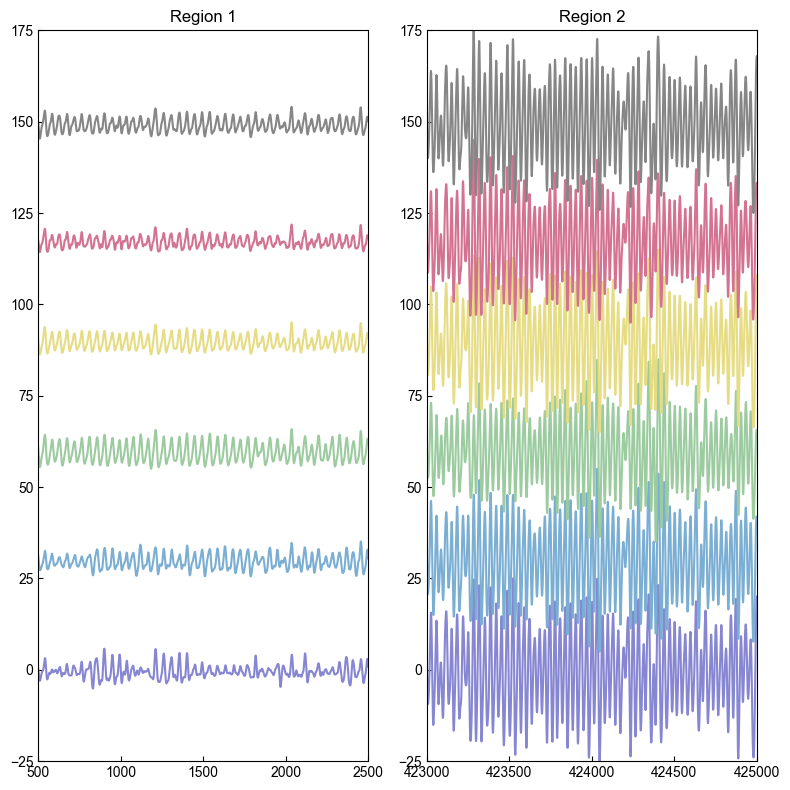

In [216]:
ppg_region_start_1 = 500
ppg_region_end_1 = 2500

ppg_region_start_2 = 423000
ppg_region_end_2 = 425000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(ppg_region_1)
ax2.set_xlim(ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

## for fig3

### AC

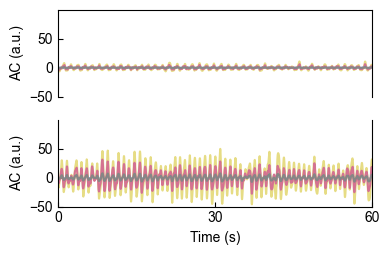

In [217]:
processor = SpectraDermaProcessor(sample_rate=50.0)
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=4.0, order=3)
timestamp, channels_ac = processor.get_data()

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(4, 2.65))
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.15)

for ch in range(channels_ac.shape[1]):
    y = channels_ac[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

# Ensure exactly three ticks on both axes for each subplot
for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('AC (a.u.)')

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-50, 100)
ax2.set_ylim(-50, 100)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

ax1.set_yticks([-50, 0, 50])
ax2.set_yticks([-50, 0, 50])


plt.tight_layout()
# plt.savefig('../figures/fig3/mode_a_ac.png', dpi=600, bbox_inches='tight', transparent=True)

pos_ax1 = ax1.get_position()
pos_ax2 = ax2.get_position()

plt.show()

### Spectra

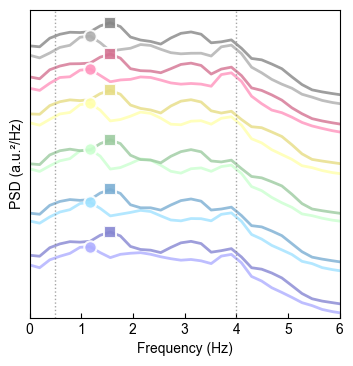

Frequency Domain Analysis - Normal vs Alcohol AC (520S2)
Channel   Normal PPG Power   Alcohol PPG Power   Difference   % Change
----------------------------------------------------------------------
415nm           3.41e-02         1.52e+00    1.49e+00    4354.1%
480nm           7.99e-02         2.57e+00    2.49e+00    3112.9%
555nm           2.30e+00         3.41e+01    3.18e+01    1381.7%
590nm           1.16e+01         4.52e+02    4.41e+02    3815.8%
680nm           2.57e+00         1.39e+02    1.37e+02    5326.9%
910nm           2.46e-01         1.02e+01    9.95e+00    4051.5%


In [ ]:
from scipy.signal import welch
from matplotlib.transforms import Bbox

# Extract AC data from both regions
normal_ac = channels_ac[ppg_region_start_1:ppg_region_end_1, :]  # Region 1 (Normal)
alcohol_ac = channels_ac[ppg_region_start_2:ppg_region_end_2, :]  # Region 2 (Alcohol)

# Calculate Power Spectral Density for both regions
sample_rate = 50.0
nperseg = 256

# Create single plot with y-offset
fig, ax = plt.subplots(figsize=(4, 4))

wavelengths = ['415nm', '480nm', '555nm', '590nm', '680nm', '910nm']
y_offset = 5  # Offset between channels in log scale

for ch in range(6):
    # Calculate PSD for both conditions
    freqs_normal, psd_normal = welch(normal_ac[:, ch], fs=sample_rate, nperseg=nperseg)
    freqs_alcohol, psd_alcohol = welch(alcohol_ac[:, ch], fs=sample_rate, nperseg=nperseg)
    
    # Apply y-offset by multiplying by offset factor
    offset_factor = 10**(ch * y_offset)
    
    # Get colors - brighter for normal, original for alcohol
    normal_color = make_color_brighter(colors[ch], factor=1.3)
    alcohol_color = colors[ch]
    
    # Plot both spectra with offset
    ax.semilogy(freqs_normal, psd_normal * offset_factor, 
                color=normal_color, linewidth=2, alpha=0.8, label=f'{wavelengths[ch]}')
    ax.semilogy(freqs_alcohol, psd_alcohol * offset_factor, 
                color=alcohol_color, linewidth=2, alpha=0.8)
    
    # Find and highlight peaks for normal condition
    normal_peak_idx = np.argmax(psd_normal * offset_factor)
    normal_peak_freq = freqs_normal[normal_peak_idx]
    normal_peak_power = psd_normal[normal_peak_idx] * offset_factor
    
    # Find and highlight peaks for alcohol condition
    alcohol_peak_idx = np.argmax(psd_alcohol * offset_factor)
    alcohol_peak_freq = freqs_alcohol[alcohol_peak_idx]
    alcohol_peak_power = psd_alcohol[alcohol_peak_idx] * offset_factor
    
    # Mark peaks with circles
    ax.scatter(normal_peak_freq, normal_peak_power, 
               color=normal_color, s=80, marker='o', alpha=0.9, 
               edgecolors='white', linewidth=1.5, zorder=5)
    ax.scatter(alcohol_peak_freq, alcohol_peak_power, 
               color=alcohol_color, s=80, marker='s', alpha=0.9, 
               edgecolors='white', linewidth=1.5, zorder=5)

# Mark physiological frequency region of interest (0.5-4.0 Hz)
ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.7, linewidth=1, label='Physiological Band')
ax.axvline(x=4.0, color='gray', linestyle=':', alpha=0.7, linewidth=1)

# Add legend elements for peak markers
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='gray', linestyle='-', 
           markersize=8, alpha=0.9, label='Normal Peak'),
    Line2D([0], [0], marker='s', color='gray', linestyle='-', 
           markersize=8, alpha=0.9, label='Alcohol Peak'),
    Line2D([0], [0], color='gray', linestyle=':', alpha=0.7, label='Physiological Band')
]

# Formatting
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD (a.u.²/Hz)')
ax.set_yticks([])  # Hide y-ticks for clarity
ax.tick_params(direction='in')
ax.set_xlim(0, 6)
ax.set_ylim(1e-10, 1e28)
ax.set_position(Bbox([[0.125, 0.10999999999999999], [0.9, 0.88]]))  # from Data_Pipeline_Wrist.ipynb

# plt.savefig('../figures/SI/figs3-placebo/frequency_domain_analysis_placebo.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Calculate and display quantitative differences
print("Frequency Domain Analysis - Normal vs Alcohol AC (520S2)")
print("=" * 70)
print("Channel   Normal PPG Power   Alcohol PPG Power   Difference   % Change")
print("-" * 70)

for ch in range(6):
    # Calculate PSD
    freqs_normal, psd_normal = welch(normal_ac[:, ch], fs=sample_rate, nperseg=nperseg)
    freqs_alcohol, psd_alcohol = welch(alcohol_ac[:, ch], fs=sample_rate, nperseg=nperseg)
    
    # Calculate power in physiological band (0.5-4.0 Hz)
    ppg_mask = (freqs_normal >= 0.5) & (freqs_normal <= 4.0)
    
    normal_power = np.trapezoid(psd_normal[ppg_mask], freqs_normal[ppg_mask])
    alcohol_power = np.trapezoid(psd_alcohol[ppg_mask], freqs_alcohol[ppg_mask])
    
    difference = alcohol_power - normal_power
    percent_change = (difference / normal_power) * 100 if normal_power > 0 else 0
    
    print(f"{wavelengths[ch]:8s}   {normal_power:13.2e}   {alcohol_power:14.2e}   "
          f"{difference:9.2e}   {percent_change:7.1f}%")

#### AC stats

In [176]:
from spectraderma_ppg_analyzer import SpectraDermaPPGAnalyzer

# Create analyzer instances for both regions
analyzer_1 = SpectraDermaPPGAnalyzer(sample_rate=50.0)
analyzer_2 = SpectraDermaPPGAnalyzer(sample_rate=50.0)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=3, order=3)

# Load data into both analyzers
analyzer_1.load_data(processor)
analyzer_2.load_data(processor)

# Set regions
analyzer_1.set_region(ppg_region_start_1, ppg_region_end_1)
analyzer_2.set_region(ppg_region_start_2, ppg_region_end_2)

print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS")
print("="*80)

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1 = analyzer_1.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_1 = analyzer_1.get_heart_rate()  # Fixed: no parameter needed
print(f"Found {len(peaks_1)} peaks, Heart Rate: {heart_rate_1:.1f} BPM")

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2 = analyzer_2.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_2 = analyzer_2.get_heart_rate()  # Fixed: no parameter needed
print(f"Found {len(peaks_2)} peaks, Heart Rate: {heart_rate_2:.1f} BPM")

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS

REGION 1 ANALYSIS
Found 44 peaks, Heart Rate: 65.9 BPM

REGION 2 ANALYSIS
Found 56 peaks, Heart Rate: 86.6 BPM



PEAK VISUALIZATION

Region 1 Visualization:


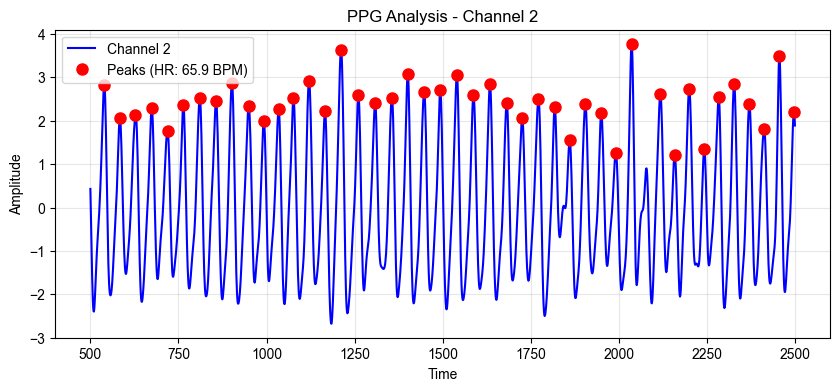


Region 2 Visualization:


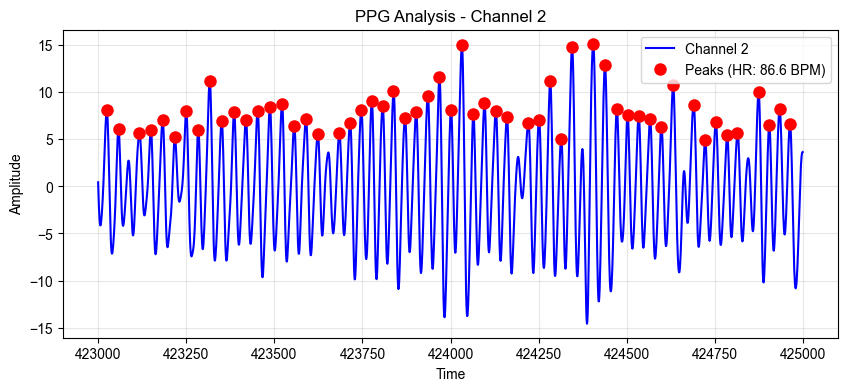

In [13]:
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

# Plot peaks for both regions using the simplified analyzer
if len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    analyzer_1.plot_peaks(channel_idx=2)

if len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    analyzer_2.plot_peaks(channel_idx=2)

#### segmentation

REGION 1 - OVERLAID WAVEFORM SEGMENTS


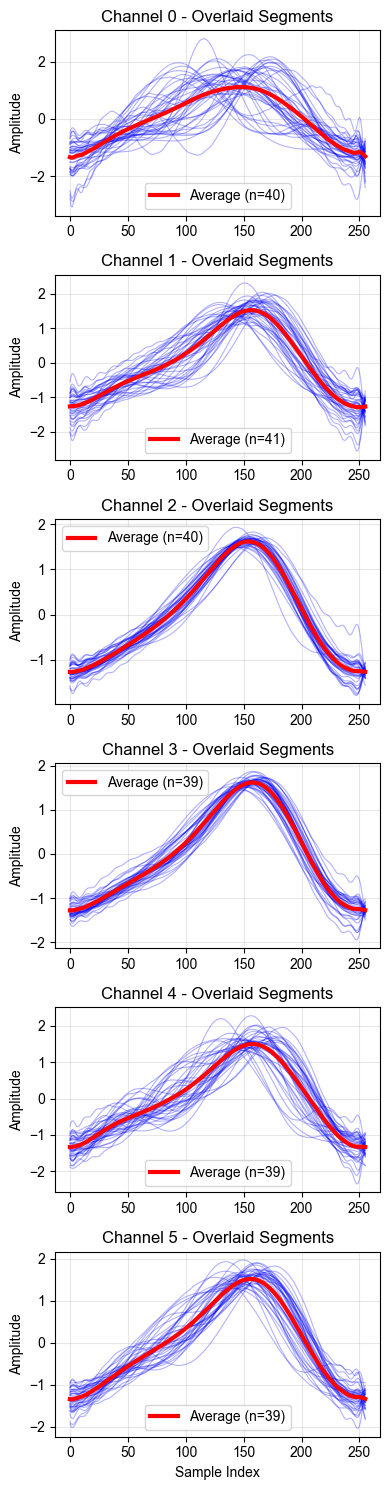

REGION 2 - OVERLAID WAVEFORM SEGMENTS


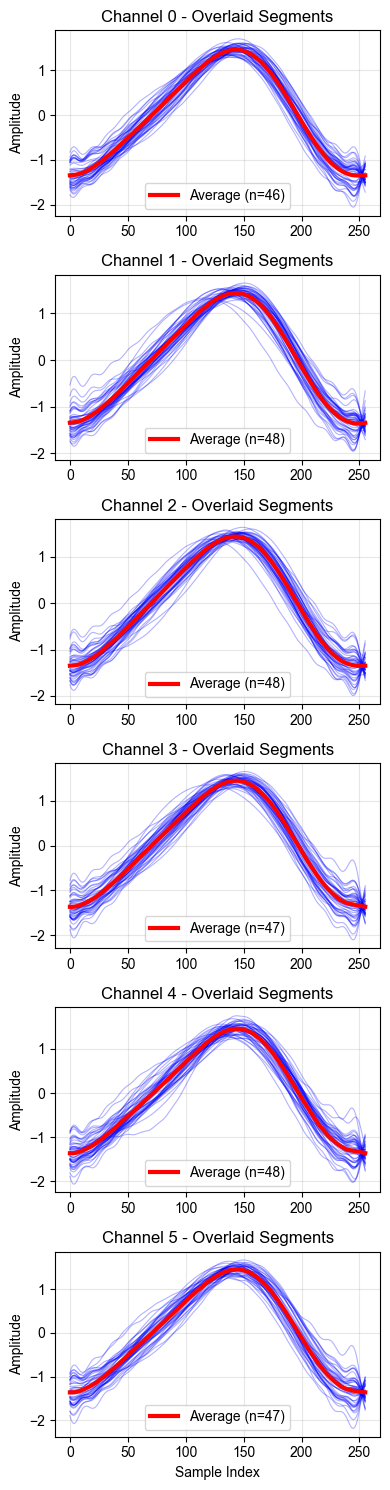

In [22]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 1 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_1.segment(outlier_sigma=3.0)
analyzer_1.plot_segments()

# Plot overlaid segments for Region 1
print("="*60)
print("REGION 2 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_2.segment(outlier_sigma=3.0)
analyzer_2.plot_segments()

##### save segments

In [23]:
analyzer_1.compile(save_path="../data/ppg_segments/520S2/normal.pt", processor=processor, num_augmentation=50)
analyzer_2.compile(save_path="../data/ppg_segments/520S2/alcohol.pt", processor=processor, num_augmentation=50)

Original metadata peek (first 5 samples, all channels):
  Sample 0: Heights=[0.38655635 0.43637555 2.83160084 7.66446027 3.87383573 1.11561073]
            Intervals=[0. 0. 0. 0. 0. 0.]
            Widths=[0.33596219 0.34543306 0.38966442 0.37936142 0.38194656 0.39114003]
  Sample 1: Heights=[0.05971512 0.32689059 2.06264106 5.34104878 2.09315179 0.86433676]
            Intervals=[0.86 0.86 0.9  0.88 0.88 0.9 ]
            Widths=[0.18688789 0.32141614 0.34378598 0.36150271 0.45169442 0.44491423]
  Sample 2: Heights=[0.13133702 0.18393083 2.13686104 5.38115889 2.24980383 0.72917313]
            Intervals=[0.94 0.9  0.88 0.9  0.88 0.84]
            Widths=[0.33998911 0.37648917 0.43087764 0.42029539 0.40522861 0.43625298]
  Sample 3: Heights=[0.22017773 0.32827743 2.30085351 6.19968076 2.9595575  0.85679847]
            Intervals=[0.86 0.94 0.92 0.92 0.94 0.96]
            Widths=[0.24067396 0.45487271 0.36129351 0.39534869 0.43173311 0.45081749]
  Sample 4: Heights=[0.17345966 0.272729

tensor([[[-0.9909, -0.9770, -0.9879, -1.0391, -1.0320, -1.0674],
         [-0.9458, -0.9338, -0.9404, -1.0038, -0.9872, -1.0331],
         [-0.9171, -0.9071, -0.9119, -0.9815, -0.9598, -1.0108],
         ...,
         [-1.2082, -1.1890, -1.2243, -1.2100, -1.2533, -1.2302],
         [-1.1253, -1.1079, -1.1336, -1.1448, -1.1685, -1.1683],
         [-1.0516, -1.0359, -1.0533, -1.0868, -1.0934, -1.1131]],

        [[-1.5737, -1.6216, -1.6751, -1.5299, -1.4799, -1.4841],
         [-1.6049, -1.6506, -1.7187, -1.5484, -1.4854, -1.4927],
         [-1.6231, -1.6656, -1.7449, -1.5590, -1.4877, -1.4968],
         ...,
         [-1.4174, -1.4664, -1.4581, -1.4364, -1.4482, -1.4372],
         [-1.4772, -1.5269, -1.5415, -1.4724, -1.4607, -1.4556],
         [-1.5304, -1.5797, -1.6151, -1.5042, -1.4715, -1.4715]],

        [[-0.8296, -0.7668, -0.7680, -0.8667, -0.8594, -0.9488],
         [-0.7659, -0.6893, -0.6886, -0.8085, -0.8065, -0.8941],
         [-0.7259, -0.6403, -0.6395, -0.7726, -0.7734, -0.

#### t-test

In [ ]:
from scipy import stats
import matplotlib.colors as mcolors
import numpy as np

def add_significance_bracket(ax, x1, x2, y, p_value, height_offset=0.1):
    """Add significance bracket to plot only if significant"""
    # Only add bracket if significant
    if p_value < 0.05:
        # Determine significance level
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = '**'
        else:
            sig_text = '*'
        
        # Draw bracket
        bracket_height = y + height_offset
        ax.plot([x1, x1, x2, x2], [y, bracket_height, bracket_height, y], 'k-', linewidth=1)
        
        # Add significance text
        ax.text((x1 + x2) / 2, bracket_height + 0.02, sig_text, 
                ha='center', va='bottom', fontsize=12, fontweight='bold')
        
        return bracket_height + 0.05
    else:
        # Return original y position if not significant (no bracket added)
        return y


wavelengths = ['415', '480', '555', '590', '680', '910']

##### violin plot 1: peak height

Peak Height Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.29±0.17      1.68±0.47      0.0000   ***
Ch1   0.45±0.15      2.23±0.56      0.0000   ***
Ch2   2.44±0.54      8.08±2.37      0.0000   ***
Ch3   5.54±1.57      28.96±8.21      0.0000   ***
Ch4   2.43±0.97      15.91±4.95      0.0000   ***
Ch5   0.78±0.24      4.33±1.27      0.0000   ***


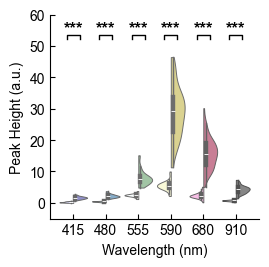

In [25]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Height Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 0, ch][~np.isnan(pulse_data_1[:, 0, ch])]
    data2 = pulse_data_2[:, 0, ch][~np.isnan(pulse_data_2[:, 0, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Height': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Height': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Height',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Height (a.u.)')
ax.set_xticks(range(6))
ax.set_xticklabels(wavelengths)
ax.set_ylim(-5, 60)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

pos_violin_ax = ax.get_position()
# plt.savefig('../figures/fig3/violin_peak_heights.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

###### NOTE: fig3 axis position

In [26]:
# pos_violin_ax

##### violin plot 2: peak interval

Peak Interval Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.89±0.19      0.69±0.19      0.0000   ***
Ch1   0.89±0.18      0.69±0.20      0.0000   ***
Ch2   0.89±0.18      0.69±0.20      0.0000   ***
Ch3   0.89±0.18      0.69±0.20      0.0000   ***
Ch4   0.89±0.19      0.69±0.19      0.0000   ***
Ch5   0.89±0.18      0.69±0.19      0.0000   ***


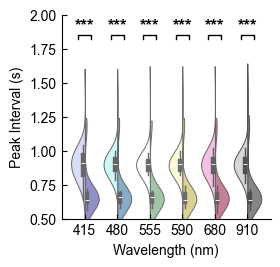

In [27]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Interval Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 1, ch][~np.isnan(pulse_data_1[:, 1, ch])]
    data2 = pulse_data_2[:, 1, ch][~np.isnan(pulse_data_2[:, 1, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Interval': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Interval': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Interval',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Interval (s)')
ax.set_xticks(range(6))
ax.set_xticklabels(wavelengths)
ax.set_ylim(0.5, 2)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

ax.set_position(pos_violin_ax)
# plt.savefig('../figures/fig3/violin_peak_intervals.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

##### violin plot 3: peak width

Peak Width Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.33±0.11      0.32±0.05      0.7435   ns
Ch1   0.36±0.08      0.33±0.09      0.0442   *
Ch2   0.36±0.06      0.32±0.04      0.0001   ***
Ch3   0.36±0.05      0.33±0.09      0.0519   ns
Ch4   0.37±0.09      0.32±0.05      0.0013   **
Ch5   0.37±0.06      0.32±0.05      0.0001   ***


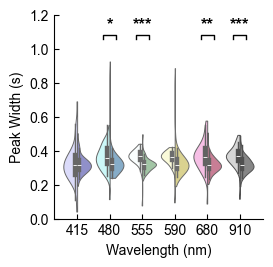

In [ ]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Width Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 2, ch][~np.isnan(pulse_data_1[:, 2, ch])]
    data2 = pulse_data_2[:, 2, ch][~np.isnan(pulse_data_2[:, 2, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Width': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Width': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Width',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Width (s)')
ax.set_xticks(range(6)) 
ax.set_xticklabels(wavelengths)
ax.set_ylim(0, 1.2)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

ax.set_position(pos_violin_ax)
# plt.savefig('../figures/fig3/violin_peak_widths.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

### DC

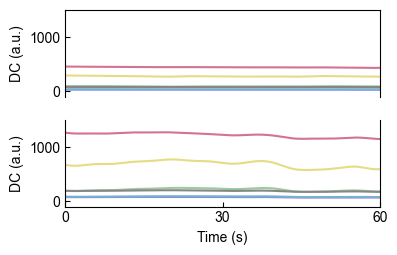

In [35]:
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).lowpass_filter(cutoff=0.2, order=3)
timestamp, channels_dc = processor.get_data()


fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(4, 2.65))

for ch in range(channels_dc.shape[1]):
    y = channels_dc[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('DC (a.u.)')

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-100, 1500)
ax2.set_ylim(-100, 1500)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

ax1.set_position(pos_ax1)
ax2.set_position(pos_ax2)

# plt.tight_layout()
# plt.savefig('../figures/fig3/mode_a_dc.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# 555S1

In [30]:
processor.load_data('../data/spectraderama_data_2025-03-26_sattac555S1.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (343404, 6)
First few rows:
     0    1     2     3    4     5
0  2.0  5.0  13.0  14.0  8.0  14.0
1  2.0  5.0  13.0  14.0  8.0  14.0
2  2.0  5.0  13.0  14.0  8.0  14.0
3  2.0  4.0  12.0  14.0  8.0  13.0
4  2.0  4.0  12.0  14.0  8.0  13.0


In [31]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=4, zero_levels=(1, 2, 3, 4))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (343404, 6)


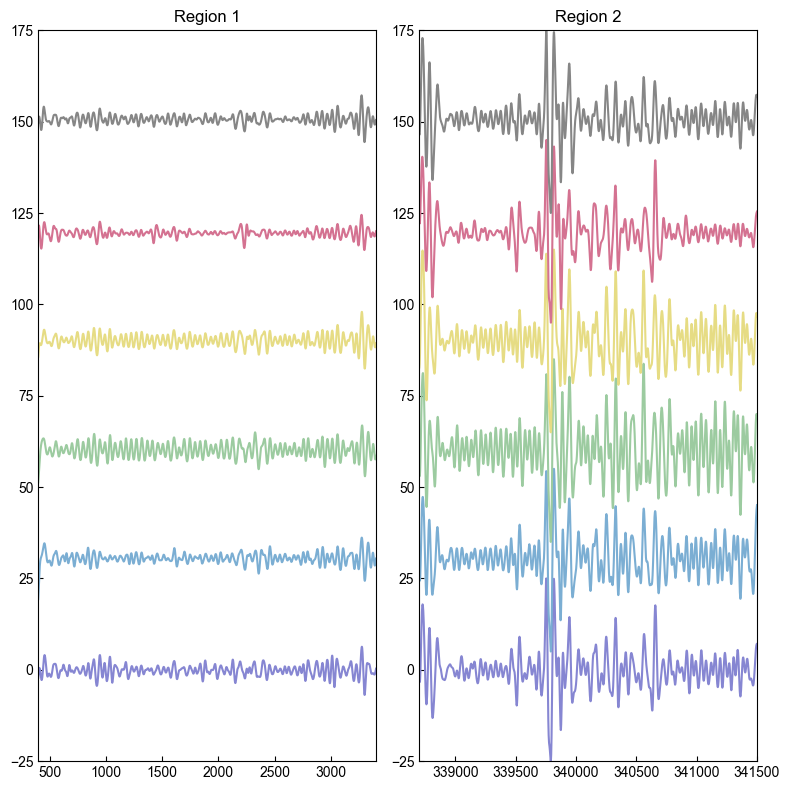

In [32]:
ppg_region_start_1 = 400
ppg_region_end_1 = 3400

ppg_region_start_2 = 338700
ppg_region_end_2 = 341500

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

#### 555S1 AC stats

In [33]:
from spectraderma_ppg_analyzer import SpectraDermaPPGAnalyzer

# Create analyzer instances for both regions
analyzer_1 = SpectraDermaPPGAnalyzer(sample_rate=50.0)
analyzer_2 = SpectraDermaPPGAnalyzer(sample_rate=50.0)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=2.5, order=3)

# Load data into both analyzers
analyzer_1.load_data(processor)
analyzer_2.load_data(processor)

# Set regions for 555S1
analyzer_1.set_region(ppg_region_start_1, ppg_region_end_1)
analyzer_2.set_region(ppg_region_start_2, ppg_region_end_2)

print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 555S1")
print("="*80)

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1 = analyzer_1.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_1 = analyzer_1.get_heart_rate()
print(f"Found {len(peaks_1)} peaks, Heart Rate: {heart_rate_1:.1f} BPM")

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2 = analyzer_2.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_2 = analyzer_2.get_heart_rate()
print(f"Found {len(peaks_2)} peaks, Heart Rate: {heart_rate_2:.1f} BPM")

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 555S1

REGION 1 ANALYSIS
Found 49 peaks, Heart Rate: 61.3 BPM

REGION 2 ANALYSIS
Found 49 peaks, Heart Rate: 64.1 BPM



PEAK VISUALIZATION

Region 1 Visualization:


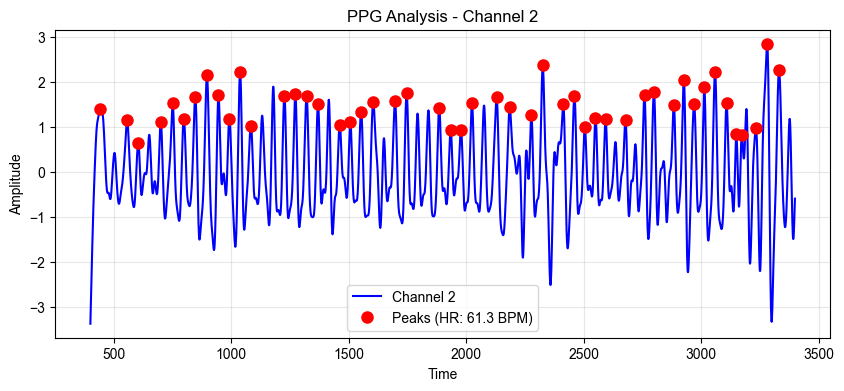


Region 2 Visualization:


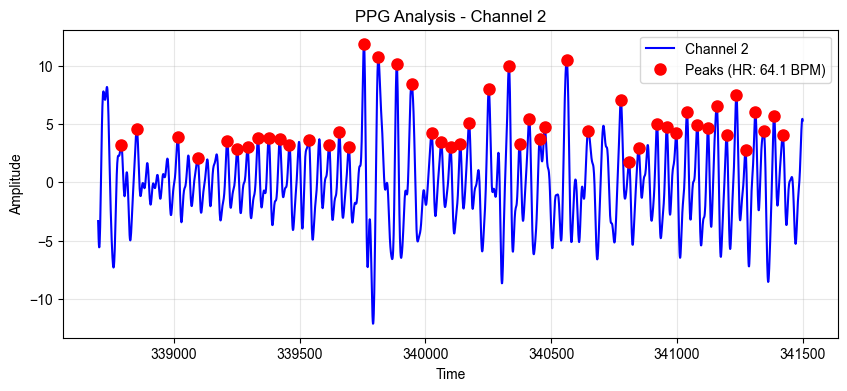

In [34]:
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

# Plot peaks for both regions using the simplified analyzer
if len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    analyzer_1.plot_peaks(channel_idx=2)

if len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    analyzer_2.plot_peaks(channel_idx=2)

#### 555S1 segmentation

REGION 1 - OVERLAID WAVEFORM SEGMENTS


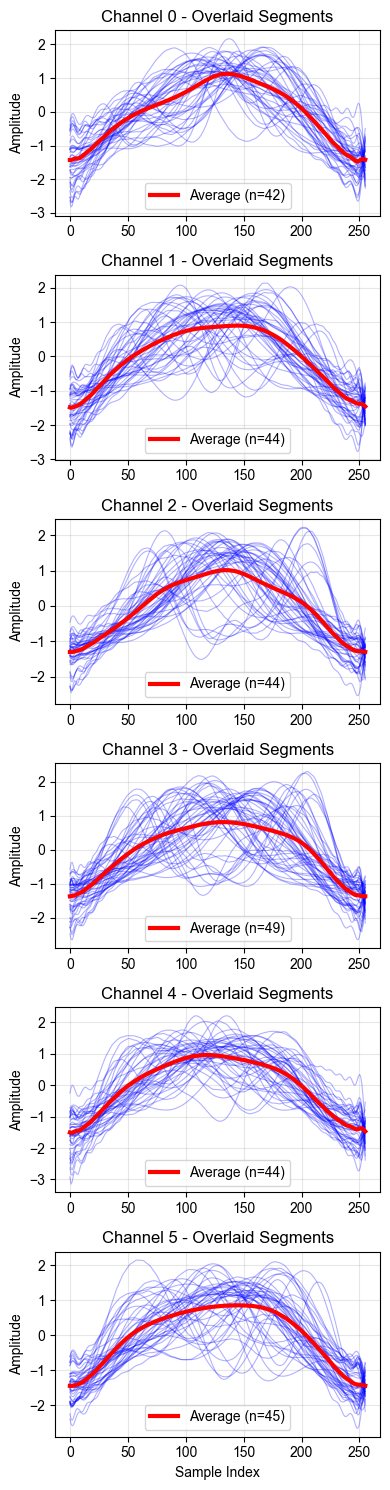

REGION 2 - OVERLAID WAVEFORM SEGMENTS


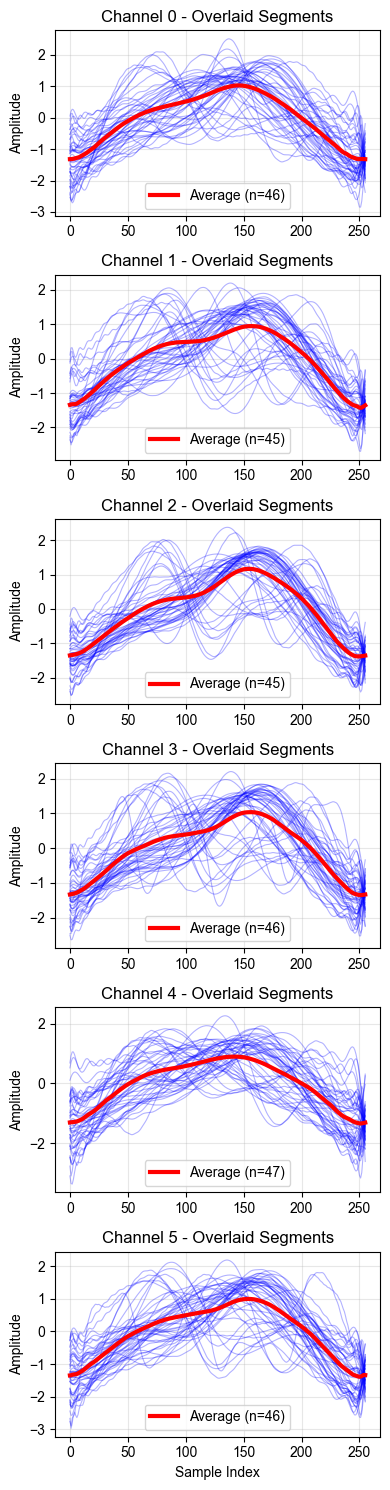

In [35]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 1 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_1.segment(outlier_sigma=1.0)
analyzer_1.plot_segments()

# Plot overlaid segments for Region 2
print("="*60)
print("REGION 2 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_2.segment(outlier_sigma=1.0)
analyzer_2.plot_segments()

#### 555S1 save segments for ML

In [36]:
analyzer_1.compile(save_path="../data/ppg_segments/555S1/normal.pt", processor=processor, num_augmentation=50)
analyzer_2.compile(save_path="../data/ppg_segments/555S1/alcohol.pt", processor=processor, num_augmentation=50)

Original metadata peek (first 5 samples, all channels):
  Sample 0: Heights=[0.3411927  0.47516461 1.39725742 2.82238486 3.07424802 0.71496775]
            Intervals=[0. 0. 0. 0. 0. 0.]
            Widths=[0.55913052 1.00788233 0.8884594  0.70311259 0.60660912 0.48573211]
  Sample 1: Heights=[0.16918473 0.24602711 1.15468039 2.08450707 1.3754927  0.25694756]
            Intervals=[2.   2.1  2.3  2.1  2.14 2.2 ]
            Widths=[0.78222347 0.83776947 0.46354067 0.72558667 0.2029641  0.82526257]
  Sample 2: Heights=[0.04583353 0.08783492 0.63030613 1.31153929 0.79458846 0.13575831]
            Intervals=[0.9  0.92 0.94 0.96 0.96 0.88]
            Widths=[0.26026624 0.18938861 0.30038196 0.3450817  0.15031972 0.25732784]
  Sample 3: Heights=[0.05505513 0.21551892 1.11415865 1.57037636 0.25628941 0.23793715]
            Intervals=[2.02 1.92 1.92 1.86 1.76 1.94]
            Widths=[0.22195234 0.43032405 0.32407554 0.37150198 0.15678569 0.75605741]
  Sample 4: Heights=[0.04099449 0.087140

tensor([[[-1.4177, -1.6463, -2.2431, -2.2481, -1.2705, -1.4289],
         [-1.3851, -1.6619, -2.3378, -2.3866, -1.2079, -1.4001],
         [-1.3692, -1.6473, -2.3421, -2.3965, -1.1799, -1.3876],
         ...,
         [-1.5923, -1.5114, -1.6035, -1.3147, -1.6154, -1.5886],
         [-1.5263, -1.5489, -1.8285, -1.6477, -1.4853, -1.5284],
         [-1.4661, -1.6018, -2.0609, -1.9851, -1.3658, -1.4730]],

        [[-2.1861, -2.2871, -2.3502, -2.1207, -2.7685, -2.6714],
         [-2.4170, -2.5053, -2.5269, -2.2670, -3.0990, -2.9759],
         [-2.3661, -2.3818, -2.4840, -2.2328, -2.9350, -2.8174],
         ...,
         [-0.4873, -0.5974, -1.0108, -1.0233, -0.1990, -0.3086],
         [-1.0238, -1.0027, -1.4454, -1.3760, -0.8708, -0.9071],
         [-1.6685, -1.6894, -1.9505, -1.7908, -1.8981, -1.8577]],

        [[-0.6803, -1.6212, -1.3074, -1.2800, -0.5815, -1.3720],
         [-0.6058, -1.6027, -1.2829, -1.2421, -0.3950, -1.2887],
         [-0.5550, -1.5924, -1.2716, -1.2248, -0.2995, -1.

# 563S2

In [64]:
processor.load_data('../data/spectraderama_data_2025-03-24_sattac563S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (31710, 6)
First few rows:
     0    1     2     3     4     5
0  2.0  6.0  18.0  18.0   9.0  13.0
1  2.0  6.0  18.0  18.0   9.0  13.0
2  2.0  6.0  18.0  18.0   9.0  13.0
3  2.0  6.0  17.0  19.0  10.0  13.0
4  3.0  6.0  17.0  19.0  10.0  13.0


In [65]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (31710, 6)


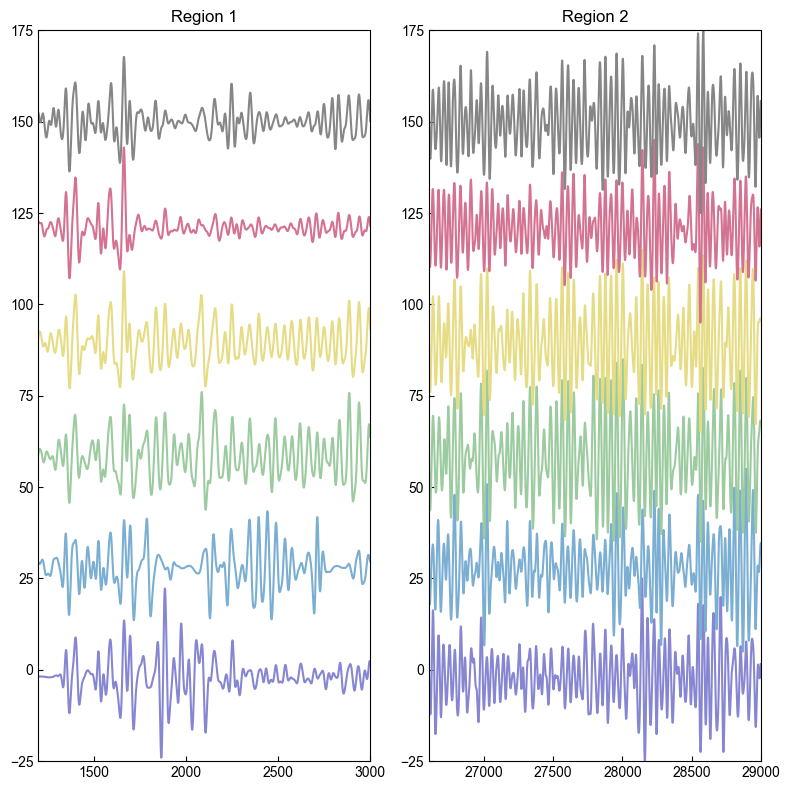

In [68]:
ppg_region_start_1 = 1200
ppg_region_end_1 = 3000

ppg_region_start_2 = 26600
ppg_region_end_2 = 29000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

#### 563S2 AC stats

In [92]:
from spectraderma_ppg_analyzer import SpectraDermaPPGAnalyzer

# Create analyzer instances for both regions
analyzer_1 = SpectraDermaPPGAnalyzer(sample_rate=50.0)
analyzer_2 = SpectraDermaPPGAnalyzer(sample_rate=50.0)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=2, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=2.8, order=3)

# Load data into both analyzers
analyzer_1.load_data(processor)
analyzer_2.load_data(processor)

# Set regions for 563S2
analyzer_1.set_region(ppg_region_start_1, ppg_region_end_1)
analyzer_2.set_region(ppg_region_start_2, ppg_region_end_2)

print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 563S2")
print("="*80)

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1 = analyzer_1.find_peaks(reference_channel=3, tolerance_samples=15)
heart_rate_1 = analyzer_1.get_heart_rate()
print(f"Found {len(peaks_1)} peaks, Heart Rate: {heart_rate_1:.1f} BPM")

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2 = analyzer_2.find_peaks(reference_channel=3, tolerance_samples=15)
heart_rate_2 = analyzer_2.get_heart_rate()
print(f"Found {len(peaks_2)} peaks, Heart Rate: {heart_rate_2:.1f} BPM")

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS - 563S2

REGION 1 ANALYSIS
Found 33 peaks, Heart Rate: 65.8 BPM

REGION 2 ANALYSIS
Found 51 peaks, Heart Rate: 67.3 BPM



PEAK VISUALIZATION

Region 1 Visualization:


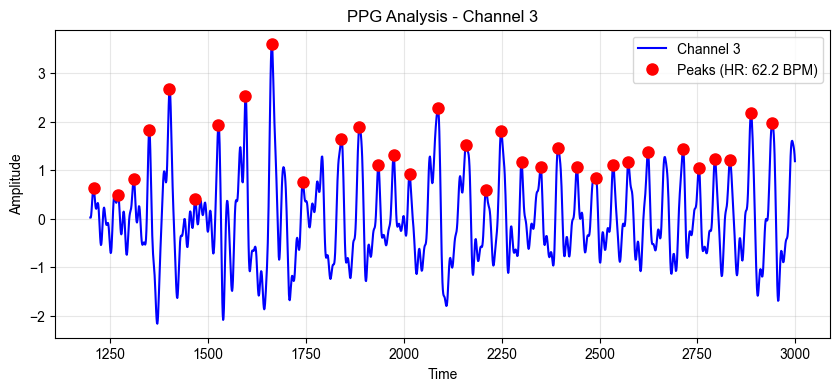


Region 2 Visualization:


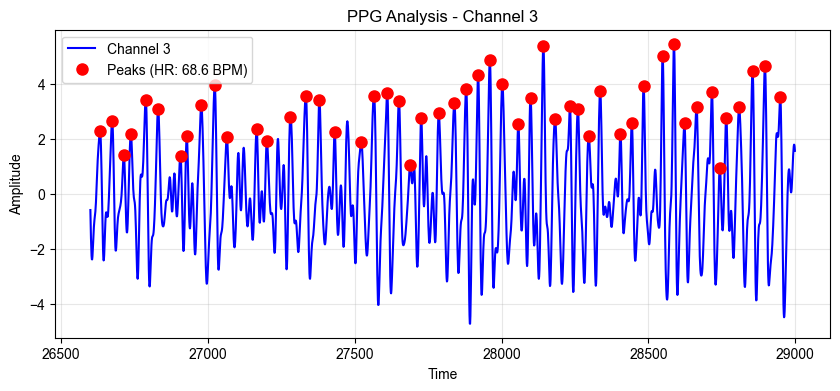

In [93]:
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

# Plot peaks for both regions using the simplified analyzer
if len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    analyzer_1.plot_peaks(channel_idx=3)

if len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    analyzer_2.plot_peaks(channel_idx=3)

#### 563S2 segmentation

REGION 1 - OVERLAID WAVEFORM SEGMENTS


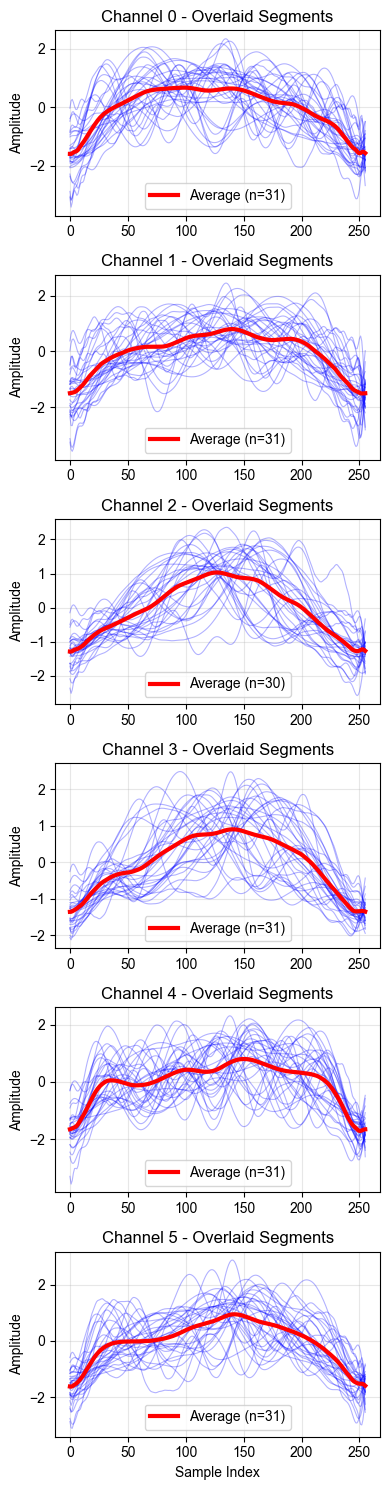

REGION 2 - OVERLAID WAVEFORM SEGMENTS


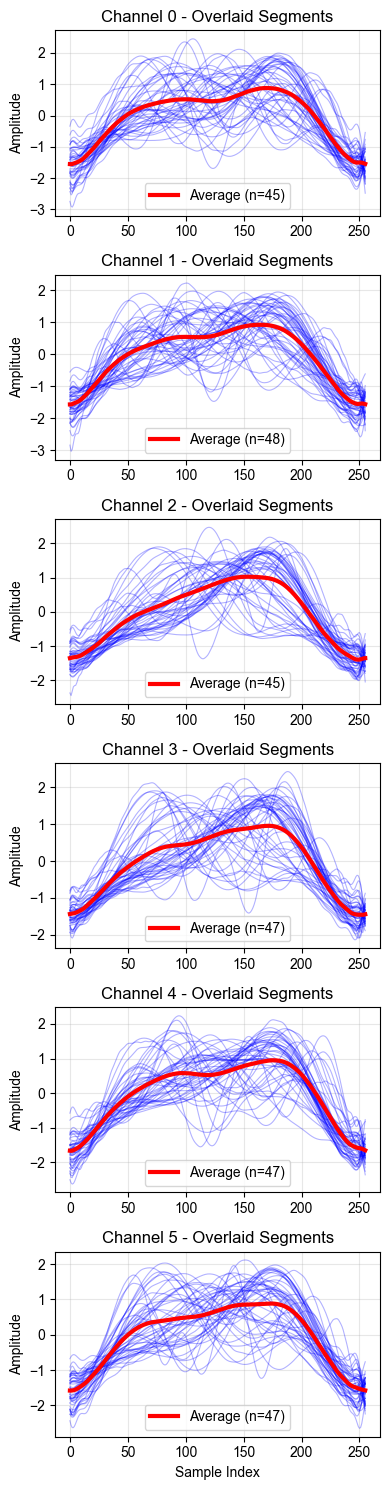

In [94]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 1 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_1.segment(outlier_sigma=0.2)
analyzer_1.plot_segments()

# Plot overlaid segments for Region 2
print("="*60)
print("REGION 2 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_2.segment(outlier_sigma=0.2)
analyzer_2.plot_segments()

#### 563S2 save segments for ML

In [95]:
import os

# Create directory for 563S2 segments
segment_dir = "../data/ppg_segments/563S2"
os.makedirs(segment_dir, exist_ok=True)

analyzer_1.compile(save_path="../data/ppg_segments/563S2/normal.pt", processor=processor, num_augmentation=50)
analyzer_2.compile(save_path="../data/ppg_segments/563S2/alcohol.pt", processor=processor, num_augmentation=50)

Original metadata peek (first 5 samples, all channels):
  Sample 0: Heights=[0.02677628 0.04944842 0.10505486 0.63153348 0.41726828 0.0651881 ]
            Intervals=[0. 0. 0. 0. 0. 0.]
            Widths=[0.13122    0.129791   0.10600671 0.15832024 0.11022081 0.05991934]
  Sample 1: Heights=[0.02580342 0.07228569 0.06942919 0.48105012 0.40066502 0.13492898]
            Intervals=[1.32 1.56 1.04 1.26 1.26 1.08]
            Widths=[0.12880114 0.14845787 0.11972284 0.39408978 0.05912572 0.1516308 ]
  Sample 2: Heights=[0.03215941 0.08358217 0.3542023  0.81732137 1.16605741 0.27744387]
            Intervals=[0.76 0.3  1.02 0.8  0.78 0.98]
            Widths=[0.12493836 0.80496225 0.23427056 0.28376558 0.31242031 0.22389684]
  Sample 3: Heights=[0.22892391 0.29736097 0.5009321  1.8223928  3.96961008 0.59030375]
            Intervals=[0.8  0.98 0.82 0.78 0.8  0.82]
            Widths=[0.18265159 0.22831719 0.21098953 0.19606553 0.19590168 0.20644164]
  Sample 4: Heights=[0.27597722 0.195717

tensor([[[-0.8235, -1.8554, -1.6578, -1.5364, -1.5193, -1.1924],
         [-0.7539, -1.8318, -1.6828, -1.5281, -1.4960, -1.1595],
         [-0.7099, -1.8155, -1.6925, -1.5193, -1.4816, -1.1413],
         ...,
         [-1.1612, -1.9611, -1.5083, -1.5563, -1.6313, -1.3637],
         [-1.0318, -1.9225, -1.5670, -1.5507, -1.5893, -1.2980],
         [-0.9174, -1.8863, -1.6183, -1.5440, -1.5510, -1.2395]],

        [[-1.7940, -1.8513, -1.4723, -1.5053, -1.5238, -1.4053],
         [-1.8158, -1.8644, -1.5168, -1.5276, -1.4929, -1.3560],
         [-1.8196, -1.8694, -1.5374, -1.5376, -1.4736, -1.3248],
         ...,
         [-1.6436, -1.7778, -1.2293, -1.3860, -1.6727, -1.6394],
         [-1.7035, -1.8058, -1.3219, -1.4310, -1.6169, -1.5520],
         [-1.7554, -1.8312, -1.4056, -1.4722, -1.5659, -1.4719]],

        [[-2.1226, -2.3886, -0.9212, -1.7944, -1.9105, -1.8068],
         [-2.1834, -2.5037, -0.8868, -1.8459, -1.9322, -1.8101],
         [-2.2108, -2.5546, -0.8660, -1.8664, -1.9379, -1.